# ENSP355 – AI in Cyber Security | Lab 1
## Recognizing Cyber Threats Using Simple AI Rules
**K.R. Mangalam University – School of Engineering & Technology** | COs: CO1, CO2 | Total: 50 marks

**Name:** _your name_  &nbsp;&nbsp; **Roll No.:** _your roll no._  &nbsp;&nbsp; **Section:** _your section_

> Safety note: only sanitized sample messages are used. Never click or open real suspicious links/files.

## General Setup

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Find the dataset whether running locally (notebooks/ or repo root) or in Colab
for path in ['simple_cyber_messages.csv',
             'data/simple_cyber_messages.csv',
             '../data/simple_cyber_messages.csv']:
    if os.path.exists(path):
        DATA_PATH = path
        break
else:
    try:                                   # Google Colab: upload the CSV manually
        from google.colab import files
        files.upload()
        DATA_PATH = 'simple_cyber_messages.csv'
    except ImportError:
        raise FileNotFoundError('simple_cyber_messages.csv not found')

df = pd.read_csv(DATA_PATH)
display(df.head())
print('Dataset shape:', df.shape)

,message_id,message,correct_category
0,1,Team meeting is scheduled for Monday at 10 AM ...,Safe
1,2,Your account has been suspended. Click here to...,Phishing
2,3,Please update your details urgently to keep yo...,Phishing
3,4,This executable is a trojan that can spread in...,Malware
4,5,Your files are encrypted. Pay in bitcoin to re...,Ransomware


Dataset shape: (28, 3)


## Q1. Manual Threat Identification (5 marks)
**Aim:** manually classify ten sample messages and note the words that influenced each decision.

I read each message *without* opening any link/attachment, assigned one category, and wrote the influencing words.

In [2]:
manual_table = df.head(10)[['message_id', 'message', 'correct_category']].copy()

# My own manual labels (decided by reading, before looking at correct_category)
manual_table['manual_label'] = ['Safe', 'Phishing', 'Phishing', 'Malware', 'Ransomware',
                                'Safe', 'Phishing', 'Malware', 'Ransomware', 'Safe']

# TODO (done): important words for each of the ten messages
manual_table['important_words'] = [
    'meeting, scheduled',
    'suspended, click here, verify, password',
    'urgently',
    'executable, trojan',
    'encrypted, bitcoin, restore files',
    'library, returned',
    'prize, login, claim',
    'spyware, attachment',
    'locked files, ransom, payment',
    'official portal'
]
manual_table['match'] = manual_table['manual_label'] == manual_table['correct_category']
display(manual_table)
print('Manual labels matching correct_category:', manual_table['match'].sum(), '/ 10')

,message_id,message,correct_category,manual_label,important_words,match
0,1,Team meeting is scheduled for Monday at 10 AM ...,Safe,Safe,"meeting, scheduled",True
1,2,Your account has been suspended. Click here to...,Phishing,Phishing,"suspended, click here, verify, password",True
2,3,Please update your details urgently to keep yo...,Phishing,Phishing,urgently,True
3,4,This executable is a trojan that can spread in...,Malware,Malware,"executable, trojan",True
4,5,Your files are encrypted. Pay in bitcoin to re...,Ransomware,Ransomware,"encrypted, bitcoin, restore files",True
5,6,The library book you borrowed has been returne...,Safe,Safe,"library, returned",True
6,7,Congratulations! You won a prize. Login to cla...,Phishing,Phishing,"prize, login, claim",True
7,8,Do not open the attachment; it contains spyware.,Malware,Malware,"spyware, attachment",True
8,9,We have locked files on your server. A ransom ...,Ransomware,Ransomware,"locked files, ransom, payment",True
9,10,Semester results are available on the official...,Safe,Safe,official portal,True


Manual labels matching correct_category: 10 / 10


**Observation:** All ten manual labels match the `correct_category` column. Each threat message has at least two indicators, except message 3, which relies on a single urgency word ("urgently") – a weak indicator that a human would still treat with suspicion.

**Why safe messages must still be checked in context:** a message with no threat words (e.g. "official portal") can still be a well-disguised attack if the sender or link is fake, so the sender and context must be verified.

## Q2. Keyword Lists and Rule-Based Classifier (10 marks)
**Aim:** create transparent keyword lists and a function that predicts the category.

**Rule:** lowercase the text → count keyword matches per category → highest score wins → all zero means *Safe*.

In [3]:
RULE_KEYWORDS = {
    'Phishing': [
        'click here', 'verify', 'password', 'urgent',
        'otp', 'prize', 'bank', 'login', 'blocked'
    ],
    'Malware': [
        'malware', 'virus', 'infected', 'attachment',
        'trojan', 'spyware', 'executable'
    ],
    'Ransomware': [
        'encrypted', 'ransom', 'bitcoin', 'restore files',
        'locked files', 'unlock', 'payment demand'
    ]
}

def classify_message(text):
    """Return (predicted_category, matched_keywords, score)."""
    text = str(text).lower()                       # step 2: lowercase
    scores = {                                     # step 3: count matches per category
        category: sum(word in text for word in words)
        for category, words in RULE_KEYWORDS.items()
    }
    predicted = max(scores, key=scores.get)        # highest-scoring category
    if scores[predicted] == 0:                     # step 4: no match -> Safe
        return 'Safe', '', 0
    matched = [word for word in RULE_KEYWORDS[predicted] if word in text]
    return predicted, ', '.join(matched), scores[predicted]

print(classify_message('Urgent: click here to verify your password'))

('Phishing', 'click here, verify, password, urgent', 4)


In [4]:
# Test messages (including one Safe example)
tests = [
    'Urgent: click here to verify your password',          # Phishing
    'Open the attachment, it may contain a trojan',        # Malware
    'Your files are encrypted, pay bitcoin to unlock',     # Ransomware
    'Lunch will be served after the seminar',              # Safe
]
for t in tests:
    print(f'{t!r}\n   -> {classify_message(t)}\n')

'Urgent: click here to verify your password'
   -> ('Phishing', 'click here, verify, password, urgent', 4)

'Open the attachment, it may contain a trojan'
   -> ('Malware', 'attachment, trojan', 2)

'Your files are encrypted, pay bitcoin to unlock'
   -> ('Ransomware', 'encrypted, bitcoin, unlock', 3)

'Lunch will be served after the seminar'
   -> ('Safe', '', 0)



**Limitation:** keyword rules miss synonyms and new attack language (e.g. "your parcel is on hold, pay a small fee") and can fire on harmless text that contains a keyword (e.g. "bank holiday"). Matching is also by substring, so "antivirus" contains "virus".

## Q3. Complete Dataset Classification and Accuracy (10 marks)
**Aim:** run the classifier on all messages and compute correct predictions and accuracy.

In [5]:
# Create empty lists to store the prediction results.
predicted_categories = []
matched_keywords_list = []
keyword_scores = []

# Read each message from the 'message' column.
for message in df['message']:
    # The function returns category, matched keywords, and score.
    category, matched_keywords, score = classify_message(message)
    predicted_categories.append(category)
    matched_keywords_list.append(matched_keywords)
    keyword_scores.append(score)

# Add the prediction results as new DataFrame columns.
df['predicted_category'] = predicted_categories
df['matched_keywords'] = matched_keywords_list
df['keyword_score'] = keyword_scores

# True when the prediction equals the correct category.
df['correct'] = df['correct_category'] == df['predicted_category']

correct_predictions = df['correct'].sum()
incorrect_predictions = len(df) - correct_predictions
accuracy = correct_predictions / len(df)

display(df[['message_id', 'correct_category', 'predicted_category',
            'matched_keywords', 'correct']])

print('Correct predictions:', correct_predictions)
print('Incorrect predictions:', incorrect_predictions)
print(f'Accuracy: {accuracy * 100:.2f}%')

# Cross-check with scikit-learn
print('sklearn accuracy_score:', accuracy_score(df['correct_category'], df['predicted_category']))

,message_id,correct_category,predicted_category,matched_keywords,correct
0,1,Safe,Safe,,True
1,2,Phishing,Phishing,"click here, verify, password",True
2,3,Phishing,Phishing,urgent,True
3,4,Malware,Malware,"trojan, executable",True
4,5,Ransomware,Ransomware,"encrypted, bitcoin, restore files",True
5,6,Safe,Safe,,True
6,7,Phishing,Phishing,"prize, login",True
7,8,Malware,Malware,"attachment, spyware",True
8,9,Ransomware,Ransomware,"ransom, locked files",True
9,10,Safe,Safe,,True


Correct predictions: 28
Incorrect predictions: 0
Accuracy: 100.00%
sklearn accuracy_score: 1.0


**Why classroom accuracy can be optimistic:** the 28 messages were written to contain obvious keywords, and the keyword lists were designed with this kind of text in mind, so 100 % is expected. Real attackers use misspellings, synonyms, other languages, images and personalised text, and real inboxes contain far more safe messages that happen to contain words like "bank" or "urgent". On real data the accuracy would be lower, and the dataset is too small to prove real-world effectiveness. **False positives** (safe → threat) and **false negatives** (threat → safe) would both appear; this dataset has none only because it is small and clean.

## Q4. Risk Level, Recommended Action and Bar Chart (10 marks)
**Rules:** Safe → *Low*; Ransomware **or** score ≥ 2 → *High*; other threats → *Medium*.

In [6]:
risk_levels = []
recommended_actions = []

for index, row in df.iterrows():
    category = row['predicted_category']
    score = row['keyword_score']

    if category == 'Safe':
        risk = 'Low'
        action = 'Continue normal caution.'
    elif category == 'Ransomware' or score >= 2:
        risk = 'High'
        action = 'Do not click/open; isolate if required and report.'
    else:
        risk = 'Medium'
        action = 'Do not interact; verify the sender and report.'

    risk_levels.append(risk)
    recommended_actions.append(action)

df['risk_level'] = risk_levels
df['recommended_action'] = recommended_actions

display(df[['message_id', 'predicted_category', 'keyword_score',
            'risk_level', 'recommended_action']])
print(df['risk_level'].value_counts())

,message_id,predicted_category,keyword_score,risk_level,recommended_action
0,1,Safe,0,Low,Continue normal caution.
1,2,Phishing,3,High,Do not click/open; isolate if required and rep...
2,3,Phishing,1,Medium,Do not interact; verify the sender and report.
3,4,Malware,2,High,Do not click/open; isolate if required and rep...
4,5,Ransomware,3,High,Do not click/open; isolate if required and rep...
5,6,Safe,0,Low,Continue normal caution.
6,7,Phishing,2,High,Do not click/open; isolate if required and rep...
7,8,Malware,2,High,Do not click/open; isolate if required and rep...
8,9,Ransomware,2,High,Do not click/open; isolate if required and rep...
9,10,Safe,0,Low,Continue normal caution.


risk_level
High      17
Low       10
Medium     1
Name: count, dtype: int64


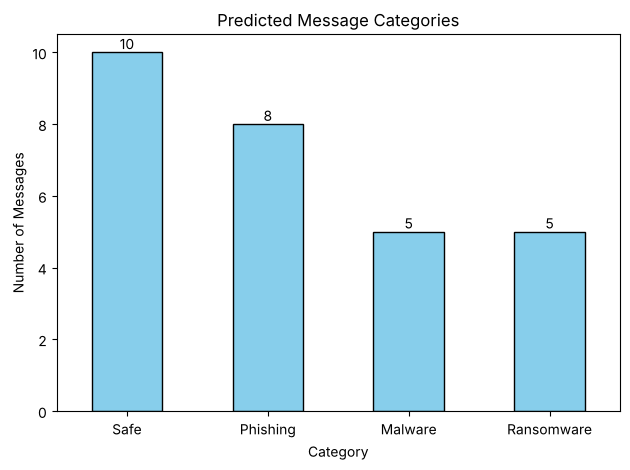

In [7]:
category_order = ['Safe', 'Phishing', 'Malware', 'Ransomware']
category_counts = df['predicted_category'].value_counts().reindex(category_order, fill_value=0)

ax = category_counts.plot(kind='bar', color='skyblue', edgecolor='black')
for p in ax.patches:                                   # value labels on the bars
    ax.annotate(int(p.get_height()),
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Predicted Message Categories')
plt.xlabel('Category')
plt.ylabel('Number of Messages')
plt.xticks(rotation=0)
plt.tight_layout()
os.makedirs('../results', exist_ok=True) if os.path.isdir('../results') or os.path.isdir('../data') else None
plt.savefig('../results/category_chart.png' if os.path.isdir('../results') else 'category_chart.png', dpi=150)
plt.show()

### Live demonstration with new messages (for the viva)

In [8]:
def analyse(text):
    category, matched, score = classify_message(text)
    row = {'predicted_category': category, 'keyword_score': score}
    if category == 'Safe':
        risk, action = 'Low', 'Continue normal caution.'
    elif category == 'Ransomware' or score >= 2:
        risk, action = 'High', 'Do not click/open; isolate if required and report.'
    else:
        risk, action = 'Medium', 'Do not interact; verify the sender and report.'
    return category, matched, score, risk, action

new_messages = [
    'URGENT: your bank account is blocked, click here to verify your OTP',
    'The attached spyware scanner report is ready',
    'Your server is hit: locked files, pay the ransom in bitcoin',
    'See you at the cricket match on Sunday',
]
demo = pd.DataFrame([(m, *analyse(m)) for m in new_messages],
                    columns=['message', 'category', 'matched', 'score', 'risk', 'action'])
display(demo)

,message,category,matched,score,risk,action
0,"URGENT: your bank account is blocked, click he...",Phishing,"click here, verify, urgent, otp, bank, blocked",6,High,Do not click/open; isolate if required and rep...
1,The attached spyware scanner report is ready,Malware,spyware,1,Medium,Do not interact; verify the sender and report.
2,"Your server is hit: locked files, pay the rans...",Ransomware,"ransom, bitcoin, locked files",3,High,Do not click/open; isolate if required and rep...
3,See you at the cricket match on Sunday,Safe,,0,Low,Continue normal caution.


In [9]:
# Known weaknesses of the rules (good to show in viva)
weak_cases = [
    ('Bank holiday on Monday, office will be closed',        'Safe (but rule flags it: false positive)'),
    ('Your parcel is on hold, pay a small fee at this link', 'Phishing (but rule says Safe: false negative)'),
]
for text, truth in weak_cases:
    print(f'{text!r}\n   truth: {truth}\n   rule : {classify_message(text)}\n')

'Bank holiday on Monday, office will be closed'
   truth: Safe (but rule flags it: false positive)
   rule : ('Phishing', 'bank', 1)

'Your parcel is on hold, pay a small fee at this link'
   truth: Phishing (but rule says Safe: false negative)
   rule : ('Safe', '', 0)



**Why High-risk results still need verification:** the rules only see keywords, not the sender, links or context. A High-risk label can be a false alarm (e.g. a security-awareness email that quotes a ransom note) and an action such as isolating a system is disruptive, so a human analyst should confirm before serious action is taken.

## Q5. Responsible Use, Reflection and File Saving (5 marks)

In [10]:
responsible_use = [
    'Privacy: remove personal identifiers before analysis.',
    'Bias: keyword lists may not cover every writing style.',
    'False alarms: safe messages may contain warning words.',
    'Accountability: humans remain responsible for action.',
    'Human review: high-risk or unclear cases must be checked.'
]
for point in responsible_use:
    print('-', point)

out_path = '../results/Lab1_Final_Result.csv' if os.path.isdir('../results') else 'Lab1_Final_Result.csv'
df.to_csv(out_path, index=False)
print('Saved:', out_path)

- Privacy: remove personal identifiers before analysis.
- Bias: keyword lists may not cover every writing style.
- False alarms: safe messages may contain warning words.
- Accountability: humans remain responsible for action.
- Human review: high-risk or unclear cases must be checked.
Saved: ../results/Lab1_Final_Result.csv


### Conclusion
Rule-based AI is simple, fast and fully transparent: every decision can be explained by the keywords that matched, which helps a security analyst trust and audit it. On the 28-message classroom dataset the classifier reached 28/28 (100 %) correct predictions, and risk levels and safe actions were assigned from the category and score. However, the rules only know the words we wrote down, so they miss synonyms and new attack wording and can raise false alarms on harmless text such as "bank holiday". Classroom accuracy is therefore optimistic. Rule-based AI should be used as a first-line helper, with privacy protection, regular rule updates and a human analyst making the final decision on high-risk or unclear cases.